# Ethanol–water distillation: VLE modelling and McCabe-Thiele column design

## Problem statement
Ethanol made by fermentation comes out dilute and has to be concentrated, usually by distillation. Designing a distillation column needs the vapour–liquid equilibrium (VLE) of the mixture: for a liquid of a given composition, what temperature does it boil at and how much ethanol is in the vapour?

The simplest model, an ideal solution (Raoult's law), is easy to use. But ethanol and water do not mix ideally, so this model is expected to give wrong boiling temperatures and vapour compositions, and it cannot show the azeotrope that stops ordinary distillation from going past a certain ethanol concentration. A model that agrees with real data is needed before any column can be designed.

## Aim
To build and validate a VLE model for ethanol–water at 1 atm in Python, and use it to estimate the reflux ratio and number of theoretical stages for a column that concentrates dilute ethanol.

## Objectives
1. Calculate the vapour pressure of pure ethanol and water with the Antoine equation.
2. Build the ideal-solution model and draw the T-x-y and x-y diagrams.
3. Compare the ideal model with published experimental data and measure the error.
4. Add activity coefficients (Wilson model), fit them to the data, and measure the improvement.
5. Use the fitted model in a McCabe-Thiele design to find the minimum reflux, operating reflux and number of stages.

## Approach and assumptions
- Pressure is 1 atm (760 mmHg) throughout.
- Wilson parameters are treated as constants for this 1 atm data set.
- McCabe-Thiele assumes constant molar overflow, a total condenser and a saturated liquid feed.
- Every number quoted in this notebook is printed by the code in the cell above the comment on it.
- Experimental data: Hadrich, B. (2009), Identification of the best model and parameters for T-y-x equilibrium data of ethanol-    water mixture.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import brentq, least_squares

## 1. Vapour pressure of the pure components
Every later calculation needs the vapour pressure of each pure liquid at a given temperature. It is calculated with the Antoine equation:

$$\log_{10} P^{sat} = A - \frac{B}{T + C}$$

with $P^{sat}$ in mmHg and $T$ in °C. A liquid boils when its vapour pressure equals the surrounding pressure, so the function is checked by confirming that each liquid gives about 760 mmHg at its normal boiling point.

In [2]:
antoine = {
    "ethanol": (8.20417, 1642.89, 230.300),
    "water": (8.07131, 1730.63, 233.426),
}
P_atm = 760.0  # mmHg

In [3]:
def p_sat(species, temp_c):
    a, b, c = antoine[species]
    return 10 ** (a - b / (temp_c + c))

In [4]:
def antoine_steps(species, temp_c):
    a, b, c = antoine[species]
    denom = temp_c + c
    ratio = b / denom
    log_p = a - ratio
    p = 10 ** log_p
    print(f"{species} at {temp_c} °C")
    print(f"  T + C       = {temp_c} + {c} = {denom:.3f}")
    print(f"  B / (T + C) = {b} / {denom:.3f} = {ratio:.4f}")
    print(f"  log10(P)    = {a} - {ratio:.4f} = {log_p:.4f}")
    print(f"  P           = 10^{log_p:.4f} = {p:.1f} mmHg")
    return p

boiling_points = {"ethanol": 78.37, "water": 100.0}
for species, t_boil in boiling_points.items():
    p = antoine_steps(species, t_boil)
    print(f"  deviation from {P_atm:.0f} mmHg: {abs(p - P_atm) / P_atm * 100:.2f} %\n")

ethanol at 78.37 °C
  T + C       = 78.37 + 230.3 = 308.670
  B / (T + C) = 1642.89 / 308.670 = 5.3225
  log10(P)    = 8.20417 - 5.3225 = 2.8817
  P           = 10^2.8817 = 761.5 mmHg
  deviation from 760 mmHg: 0.20 %

water at 100.0 °C
  T + C       = 100.0 + 233.426 = 333.426
  B / (T + C) = 1730.63 / 333.426 = 5.1904
  log10(P)    = 8.07131 - 5.1904 = 2.8809
  P           = 10^2.8809 = 760.1 mmHg
  deviation from 760 mmHg: 0.01 %



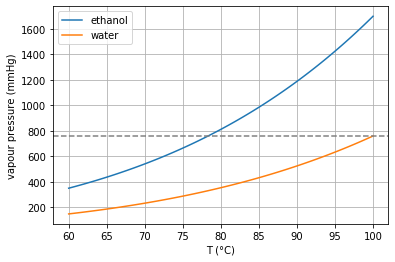

In [5]:
temps = np.linspace(60, 100, 100)
plt.plot(temps, p_sat("ethanol", temps), label="ethanol")
plt.plot(temps, p_sat("water", temps), label="water")
plt.axhline(P_atm, color="grey", linestyle="--")
plt.xlabel("T (°C)")
plt.ylabel("vapour pressure (mmHg)")
plt.legend()
plt.grid(True)
plt.show()

In [6]:
bp_ethanol = brentq(lambda t: p_sat("ethanol", t) - P_atm, 50, 110)
bp_water = brentq(lambda t: p_sat("water", t) - P_atm, 50, 110)
ethanol_always_higher = bool(np.all(p_sat("ethanol", temps) > p_sat("water", temps)))

print(f"Temperature at which the equation gives exactly {P_atm:.0f} mmHg:")
print(f"  ethanol {bp_ethanol:.2f} °C, water {bp_water:.2f} °C")
print(f"Ethanol vapour pressure above water at every temperature from {temps[0]:.0f} to {temps[-1]:.0f} °C: {ethanol_always_higher}")

Temperature at which the equation gives exactly 760 mmHg:
  ethanol 78.32 °C, water 100.00 °C
Ethanol vapour pressure above water at every temperature from 60 to 100 °C: True


**Reading the results.** The printed steps show the Antoine equation worked out by hand for each liquid, and the check shows both values land within a fraction of a percent of 760 mmHg at the accepted boiling points. The small gap exists because the constants come from a curve fit, so the equation reaches exactly 760 mmHg at a slightly different temperature than the accepted boiling point. The last line confirms ethanol is the more volatile component at every temperature in the range, and this difference in volatility is what makes distillation possible.

## 2. Ideal solution model (Raoult's law)
For an ideal mixture each component's partial pressure is its liquid mole fraction times its pure vapour pressure. The mixture boils when the partial pressures add up to the total pressure:

$$x\,P^{sat}_{ethanol}(T) + (1-x)\,P^{sat}_{water}(T) = P$$

This cannot be rearranged for $T$, so it is solved numerically for each composition. The vapour composition then follows from $y = x\,P^{sat}_{ethanol}/P$.

In [7]:
def ideal_bubble_temp(x):
    residual = lambda t: x * p_sat("ethanol", t) + (1 - x) * p_sat("water", t) - P_atm
    return brentq(residual, 50, 110)

def ideal_vapour(x, t):
    return x * p_sat("ethanol", t) / P_atm

In [8]:
x_grid = np.linspace(0, 1, 101)
t_ideal = np.array([ideal_bubble_temp(x) for x in x_grid])
y_ideal = ideal_vapour(x_grid, t_ideal)

In [9]:
check = pd.DataFrame({"x": [0.0, 0.2, 0.5, 0.8, 1.0]})
check["T_bubble (°C)"] = check["x"].apply(ideal_bubble_temp).round(2)
check["y"] = ideal_vapour(check["x"], check["T_bubble (°C)"]).round(4)
check

,x,T_bubble (°C),y
0,0.0,100.00,0.0000
1,0.2,93.88,0.3602
2,0.5,86.81,0.6942
3,0.8,81.35,0.9013
4,1.0,78.32,1.0000


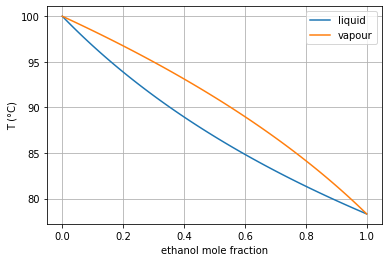

In [10]:
plt.plot(x_grid, t_ideal, label="liquid")
plt.plot(y_ideal, t_ideal, label="vapour")
plt.xlabel("ethanol mole fraction")
plt.ylabel("T (°C)")
plt.legend()
plt.grid(True)
plt.show()

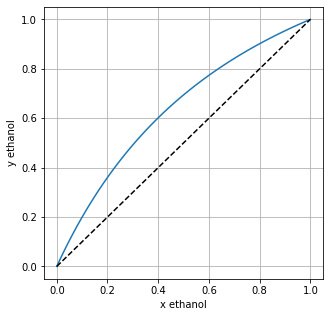

In [11]:
plt.figure(figsize=(5, 5))
plt.plot(x_grid, y_ideal)
plt.plot([0, 1], [0, 1], "k--")
plt.xlabel("x ethanol")
plt.ylabel("y ethanol")
plt.grid(True)
plt.show()

In [12]:
above_diagonal = bool(np.all(y_ideal[1:-1] > x_grid[1:-1]))
print(f"Bubble point falls from {t_ideal[0]:.2f} °C (pure water) to {t_ideal[-1]:.2f} °C (pure ethanol)")
print(f"Ideal vapour richer in ethanol than the liquid at every interior composition: {above_diagonal}")
print(f"So the ideal model predicts an azeotrope: {not above_diagonal}")

Bubble point falls from 100.00 °C (pure water) to 78.32 °C (pure ethanol)
Ideal vapour richer in ethanol than the liquid at every interior composition: True
So the ideal model predicts an azeotrope: False


**Reading the results.** The boiling temperature falls steadily from the water end to the ethanol end, and the vapour is always richer in ethanol than the liquid. The x-y curve never meets the diagonal, so this model predicts that distillation could produce 100% ethanol. That is not what happens in practice because of the azeotrope, so the ideal model needs to be tested against real data.

## 3. Experimental data against the ideal model
Published VLE data for ethanol–water at 1 atm (in mole fractions) is loaded and compared with the ideal model. The mean absolute error in boiling temperature and in vapour composition measures how wrong the model is.

In [13]:
vle = pd.read_csv("ethanol_water_vle_1atm.csv")
vle.describe()

,T_C,x_ethanol,y_ethanol
count,15.000000,15.000000,15.000000
mean,82.793333,0.374307,0.579193
std,4.762034,0.269307,0.175715
min,78.150000,0.019000,0.170000
25%,79.500000,0.144950,0.489650
50%,81.500000,0.327300,0.582600
75%,84.700000,0.546500,0.672000
max,95.500000,0.894300,0.894300


In [14]:
assert ((vle[["x_ethanol", "y_ethanol"]] >= 0) & (vle[["x_ethanol", "y_ethanol"]] <= 1)).all().all()
vle["t_ideal"] = vle["x_ethanol"].apply(ideal_bubble_temp)
vle["y_ideal"] = ideal_vapour(vle["x_ethanol"], vle["t_ideal"])
err_y_ideal = (vle["y_ideal"] - vle["y_ethanol"]).abs().mean()
err_t_ideal = (vle["t_ideal"] - vle["T_C"]).abs().mean()
print(f"Ideal model, mean absolute error in y: {err_y_ideal:.3f}")
print(f"Ideal model, mean absolute error in T: {err_t_ideal:.2f} °C")

Ideal model, mean absolute error in y: 0.118
Ideal model, mean absolute error in T: 7.45 °C


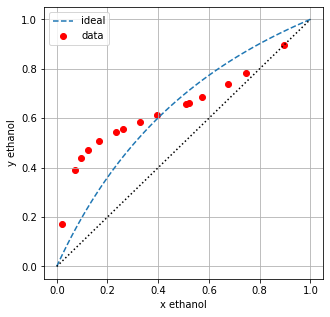

In [15]:
plt.figure(figsize=(5, 5))
plt.plot(x_grid, y_ideal, "--", label="ideal")
plt.scatter(vle["x_ethanol"], vle["y_ethanol"], color="red", label="data")
plt.plot([0, 1], [0, 1], "k:")
plt.xlabel("x ethanol")
plt.ylabel("y ethanol")
plt.legend()
plt.grid(True)
plt.show()

In [16]:
gap = vle["y_ethanol"] - vle["y_ideal"]
richer = vle[gap > 0]
leaner = vle[gap < 0]
az_row = (vle["y_ethanol"] - vle["x_ethanol"]).abs().idxmin()
data_az_x = vle.loc[az_row, "x_ethanol"]
data_az_t = vle.loc[az_row, "T_C"]

print(f"{len(vle)} data points")
print(f"Real vapour richer in ethanol than the ideal model at {len(richer)} points (x from {richer['x_ethanol'].min():.3f} to {richer['x_ethanol'].max():.3f})")
print(f"Real vapour leaner than the ideal model at {len(leaner)} points (x from {leaner['x_ethanol'].min():.3f} to {leaner['x_ethanol'].max():.3f})")
print(f"Point where vapour and liquid compositions are closest (azeotrope): x = {data_az_x:.4f}, T = {data_az_t:.2f} °C")

15 data points
Real vapour richer in ethanol than the ideal model at 9 points (x from 0.019 to 0.397)
Real vapour leaner than the ideal model at 6 points (x from 0.508 to 0.894)
Point where vapour and liquid compositions are closest (azeotrope): x = 0.8943, T = 78.15 °C


**Reading the results.** The errors above show the ideal model is far from the data. It misses in both directions, predicting too little ethanol in the vapour at low ethanol content and too much at higher ethanol content, and the data reaches the diagonal at the azeotrope, which the ideal model cannot reproduce. This confirms the ideal model is not good enough for column design.

## 4. Wilson activity coefficients fitted to the data
Ethanol and water attract each other differently from how they attract themselves, so ethanol escapes from water more readily than Raoult's law says. The correction is an activity coefficient $\gamma$ for each component (modified Raoult's law):

$$y_i P = x_i\,\gamma_i\,P^{sat}_i(T)$$

The Wilson model gives $\gamma$ from the composition, using two parameters $\Lambda_{12}$ and $\Lambda_{21}$ (1 = ethanol, 2 = water):

$$\ln\gamma_1 = -\ln(x_1+\Lambda_{12}x_2) + x_2\left(\frac{\Lambda_{12}}{x_1+\Lambda_{12}x_2}-\frac{\Lambda_{21}}{x_2+\Lambda_{21}x_1}\right)$$

$$\ln\gamma_2 = -\ln(x_2+\Lambda_{21}x_1) - x_1\left(\frac{\Lambda_{12}}{x_1+\Lambda_{12}x_2}-\frac{\Lambda_{21}}{x_2+\Lambda_{21}x_1}\right)$$

The two parameters are found by least squares: the values that make the predicted boiling temperatures and vapour compositions closest to the data points. Temperature errors are measured in °C and vapour errors in units of 0.01, so both count equally in the fit.

In [17]:
def wilson_gamma(x, l12, l21):
    x1, x2 = x, 1 - x
    a = x1 + l12 * x2
    b = x2 + l21 * x1
    shared = l12 / a - l21 / b
    gamma1 = np.exp(-np.log(a) + x2 * shared)
    gamma2 = np.exp(-np.log(b) - x1 * shared)
    return gamma1, gamma2

def real_bubble_temp(x, l12, l21):
    g1, g2 = wilson_gamma(x, l12, l21)
    residual = lambda t: x * g1 * p_sat("ethanol", t) + (1 - x) * g2 * p_sat("water", t) - P_atm
    return brentq(residual, 50, 110)

def real_vapour(x, t, l12, l21):
    g1, _ = wilson_gamma(x, l12, l21)
    return x * g1 * p_sat("ethanol", t) / P_atm

In [18]:
def misfit(params):
    l12, l21 = params
    out = []
    for x, y, t in zip(vle["x_ethanol"], vle["y_ethanol"], vle["T_C"]):
        t_calc = real_bubble_temp(x, l12, l21)
        y_calc = real_vapour(x, t_calc, l12, l21)
        out += [(t_calc - t) / 1.0, (y_calc - y) / 0.01]
    return out

result = least_squares(misfit, x0=[0.5, 0.5], bounds=([0.01, 0.01], [10, 10]))
L12, L21 = result.x
print(f"Fitted parameters: L12 = {L12:.4f}, L21 = {L21:.4f}  (converged: {result.success})")

Fitted parameters: L12 = 0.1883, L21 = 0.8597  (converged: True)


In [19]:
vle["t_wilson"] = [real_bubble_temp(x, L12, L21) for x in vle["x_ethanol"]]
vle["y_wilson"] = [real_vapour(x, t, L12, L21) for x, t in zip(vle["x_ethanol"], vle["t_wilson"])]
err_y_wilson = (vle["y_wilson"] - vle["y_ethanol"]).abs().mean()
err_t_wilson = (vle["t_wilson"] - vle["T_C"]).abs().mean()
print(f"Ideal model : error in y = {err_y_ideal:.3f}, error in T = {err_t_ideal:.2f} °C")
print(f"Wilson model: error in y = {err_y_wilson:.3f}, error in T = {err_t_wilson:.2f} °C")
print(f"Reduction   : y {100 * (1 - err_y_wilson / err_y_ideal):.0f} %, T {100 * (1 - err_t_wilson / err_t_ideal):.0f} %")

Ideal model : error in y = 0.118, error in T = 7.45 °C
Wilson model: error in y = 0.006, error in T = 0.16 °C
Reduction   : y 95 %, T 98 %


In [20]:
x_fine = np.linspace(0.001, 0.999, 300)
t_fine = np.array([real_bubble_temp(x, L12, L21) for x in x_fine])
y_fine = real_vapour(x_fine, t_fine, L12, L21)

crossing = np.where(np.diff(np.sign(y_fine - x_fine)) != 0)[0]
az_x, az_t = x_fine[crossing[0]], t_fine[crossing[0]]
print(f"Model azeotrope: x = {az_x:.3f}, T = {az_t:.2f} °C")
print(f"Data azeotrope : x = {data_az_x:.3f}, T = {data_az_t:.2f} °C")

Model azeotrope: x = 0.899, T = 78.15 °C
Data azeotrope : x = 0.894, T = 78.15 °C


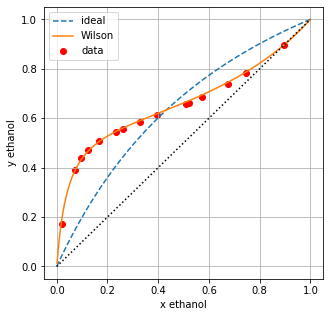

In [21]:
plt.figure(figsize=(5, 5))
plt.plot(x_grid, y_ideal, "--", label="ideal")
plt.plot(x_fine, y_fine, label="Wilson")
plt.scatter(vle["x_ethanol"], vle["y_ethanol"], color="red", label="data")
plt.plot([0, 1], [0, 1], "k:")
plt.xlabel("x ethanol")
plt.ylabel("y ethanol")
plt.legend()
plt.grid(True)
plt.show()

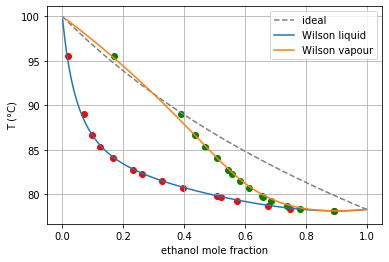

In [22]:
plt.plot(x_grid, t_ideal, "--", color="grey", label="ideal")
plt.plot(x_fine, t_fine, label="Wilson liquid")
plt.plot(y_fine, t_fine, label="Wilson vapour")
plt.scatter(vle["x_ethanol"], vle["T_C"], color="red")
plt.scatter(vle["y_ethanol"], vle["T_C"], color="green")
plt.xlabel("ethanol mole fraction")
plt.ylabel("T (°C)")
plt.legend()
plt.grid(True)
plt.show()

**Reading the results.** The printed errors compare the two models on the same data, and the Wilson model is far closer on both boiling temperature and vapour composition. The Wilson curve passes through the data points on both diagrams, and the fitted model locates the azeotrope close to where the data shows it, which the ideal model could not do at all.

## 5. McCabe-Thiele column design
With a model that matches the data, a column can be designed. The task is to concentrate a dilute feed to a distillate below the azeotrope composition found in section 4, because ordinary distillation cannot go beyond it. The fitted equilibrium curve is used with two operating lines (from material balances), and the stages are stepped off between the curve and the operating lines. Each step is one theoretical stage.

The minimum reflux is found by checking every point between the feed and the distillate, because the equilibrium curve is S-shaped and the pinch can occur away from the feed. The operating reflux is a multiple of the minimum. The design inputs are set in the first cell below.

In [23]:
z_feed = 0.05
x_top = 0.85
x_bottom = 0.002
reflux_multiple = 1.3

assert x_top < az_x, "distillate must be below the azeotrope"

In [24]:
def y_equilibrium(x):
    return np.interp(x, x_fine, y_fine)

def x_equilibrium(y):
    return np.interp(y, y_fine, x_fine)

In [25]:
x_scan = np.linspace(z_feed, x_top - 1e-3, 500)
slopes = (x_top - y_equilibrium(x_scan)) / (x_top - x_scan)
m_limit = slopes.max()
x_pinch = x_scan[slopes.argmax()]
reflux_min = m_limit / (1 - m_limit)
reflux = reflux_multiple * reflux_min

print(f"Pinch at x = {x_pinch:.3f}, y = {y_equilibrium(x_pinch):.3f}")
print(f"Steepest allowed slope of the rectifying line: {m_limit:.3f}")
print(f"Minimum reflux ratio  = m / (1 - m) = {reflux_min:.2f}")
print(f"Operating reflux ratio = {reflux_multiple} x {reflux_min:.2f} = {reflux:.2f}")

Pinch at x = 0.050, y = 0.331
Steepest allowed slope of the rectifying line: 0.649
Minimum reflux ratio  = m / (1 - m) = 1.85
Operating reflux ratio = 1.3 x 1.85 = 2.40


In [26]:
def rectifying(x):
    return reflux / (reflux + 1) * x + x_top / (reflux + 1)

y_at_feed = rectifying(z_feed)
m_strip = (y_at_feed - x_bottom) / (z_feed - x_bottom)

def stripping(x):
    return x_bottom + m_strip * (x - x_bottom)

In [27]:
path = [(x_top, x_top)]
rows = []
x = y = x_top
n_stages = 0
feed_stage = None
above_feed = True

while x > x_bottom and n_stages < 200:
    y_leaving = y
    x = x_equilibrium(y)
    path.append((x, y))
    n_stages += 1
    section = "rectifying" if above_feed else "stripping"
    if above_feed and x <= z_feed:
        above_feed = False
        feed_stage = n_stages
    rows.append((n_stages, x, y_leaving, section))
    y = rectifying(x) if above_feed else stripping(x)
    path.append((x, y))

stages = pd.DataFrame(rows, columns=["stage", "x liquid", "y vapour", "section"]).round(4)
stages

,stage,x liquid,y vapour,section
0,1,0.8382,0.8500,rectifying
1,2,0.8271,0.8417,rectifying
2,3,0.8163,0.8338,rectifying
3,4,0.8056,0.8262,rectifying
4,5,0.7948,0.8187,rectifying
5,6,0.7835,0.8110,rectifying
6,7,0.7714,0.8030,rectifying
7,8,0.7583,0.7945,rectifying
8,9,0.7435,0.7852,rectifying
9,10,0.7264,0.7748,rectifying


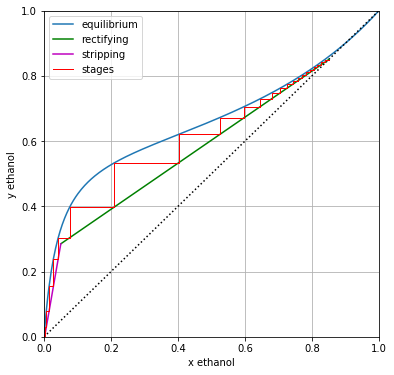

In [28]:
path = np.array(path)
plt.figure(figsize=(6, 6))
plt.plot(x_fine, y_fine, label="equilibrium")
plt.plot([0, 1], [0, 1], "k:")
plt.plot([z_feed, x_top], [rectifying(z_feed), rectifying(x_top)], "g", label="rectifying")
plt.plot([x_bottom, z_feed], [stripping(x_bottom), stripping(z_feed)], "m", label="stripping")
plt.plot(path[:, 0], path[:, 1], "r", lw=1, label="stages")
plt.xlabel("x ethanol")
plt.ylabel("y ethanol")
plt.legend()
plt.grid(True)
plt.xlim(0, 1)
plt.ylim(0, 1)
plt.show()

In [29]:
n_rect = int((stages["section"] == "rectifying").sum())
n_strip = int((stages["section"] == "stripping").sum())
print(f"Horizontal steps counted (one per theoretical stage): {len(stages)}")
print(f"  rectifying section: {n_rect}, stripping section: {n_strip}")
print(f"Feed enters at stage {feed_stage} from the top")
print(f"Total theoretical stages (including the reboiler): {n_stages}")
print(f"Smallest step in x: {stages['x liquid'].diff().abs().min():.4f} (near the top, close to the azeotrope)")

Horizontal steps counted (one per theoretical stage): 24
  rectifying section: 19, stripping section: 5
Feed enters at stage 19 from the top
Total theoretical stages (including the reboiler): 24
Smallest step in x: 0.0013 (near the top, close to the azeotrope)


**Reading the results.** The table lists every stage: the liquid and vapour compositions leaving it and the section of the column it belongs to. Counting the rows gives the number of theoretical stages, and the stage where the step crosses the feed composition is the feed stage. The steps become very small near the top because the equilibrium curve pinches against the diagonal close to the azeotrope. This is why many stages are needed even for a modest distillate purity, and why purity beyond the azeotrope is not possible by this method.

## Results summary

In [30]:
summary = pd.DataFrame({
    "mean error in y": [err_y_ideal, err_y_wilson],
    "mean error in T (°C)": [err_t_ideal, err_t_wilson],
}, index=["ideal model", "Wilson model"]).round(3)
summary

,mean error in y,mean error in T (°C)
ideal model,0.118,7.446
Wilson model,0.006,0.160


In [31]:
print(f"Wilson parameters : L12 = {L12:.4f}, L21 = {L21:.4f}")
print(f"Azeotrope (model) : x = {az_x:.3f}, T = {az_t:.2f} °C")
print(f"Azeotrope (data)  : x = {data_az_x:.3f}, T = {data_az_t:.2f} °C")
print(f"Design inputs     : feed {z_feed}, distillate {x_top}, bottoms {x_bottom}")
print(f"Design results    : R_min = {reflux_min:.2f}, R = {reflux:.2f}, stages = {n_stages}, feed stage = {feed_stage}")

Wilson parameters : L12 = 0.1883, L21 = 0.8597
Azeotrope (model) : x = 0.899, T = 78.15 °C
Azeotrope (data)  : x = 0.894, T = 78.15 °C
Design inputs     : feed 0.05, distillate 0.85, bottoms 0.002
Design results    : R_min = 1.85, R = 2.40, stages = 24, feed stage = 19


## Conclusion
The problem set at the start, a VLE model accurate enough for column design, has been solved for ethanol–water at 1 atm. The numbers behind each statement are printed in the cell that follows.

In [32]:
print(f"1. The ideal model gave a mean error of {err_t_ideal:.2f} °C in boiling temperature and {err_y_ideal:.3f} in vapour composition, and it predicted no azeotrope.")
print(f"2. Wilson activity coefficients fitted to the data cut these errors to {err_t_wilson:.2f} °C and {err_y_wilson:.3f}, and the model located the azeotrope at {az_x:.3f} mole fraction and {az_t:.2f} °C (data: {data_az_x:.3f} and {data_az_t:.2f} °C).")
print(f"3. The validated model was used in a McCabe-Thiele design for a {z_feed:.0%} feed concentrated to {x_top:.0%} distillate: minimum reflux ratio {reflux_min:.2f}, and {n_stages} theoretical stages at a reflux ratio of {reflux:.2f}.")

1. The ideal model gave a mean error of 7.45 °C in boiling temperature and 0.118 in vapour composition, and it predicted no azeotrope.
2. Wilson activity coefficients fitted to the data cut these errors to 0.16 °C and 0.006, and the model located the azeotrope at 0.899 mole fraction and 78.15 °C (data: 0.894 and 78.15 °C).
3. The validated model was used in a McCabe-Thiele design for a 5% feed concentrated to 85% distillate: minimum reflux ratio 1.85, and 24 theoretical stages at a reflux ratio of 2.40.


## Limitations
- The Wilson parameters were fitted and checked on the same data points, and the model was not tested on a separate data set.
- It is valid only near 1 atm, and the data has no points between the azeotrope and pure ethanol.
- McCabe-Thiele assumes constant molar overflow. Real columns need more trays than theoretical stages, depending on tray efficiency.
- Reaching purities beyond the azeotrope would need another method, such as extractive distillation or molecular sieves.

## References
- Hadrich, B. (2009). Identification of the best model and parameters for T-y-x equilibrium data of ethanol-water mixture.
  https://www.researchgate.net/publication/272686708_IDENTIFICATION_OF_THE_BEST_MODEL_AND_PARAMETERS_FOR_T-Y-X_EQUILIBRIUM_DATA_OF_ETHANOL-WATER_MIXTURE
- Antoine constants: Perry, R. H. & Green, D. W. (Eds.), Perry's Chemical Engineers' Handbook, 8th edition, McGraw-Hill.
- Wilson, G. M. (1964). Vapor-liquid equilibrium. XI: A new expression for the excess free energy of mixing. Journal of the American Chemical Society, 86(2), 127-130.